# Tutorial 7 — Van Gurp–Palmen and Cole–Cole plots

`hermes_rheo.visualization` provides two diagnostic plots for oscillatory
data. Both take an experiment set and read the variable names and units from
its datasets.

| Function | x | y |
|---|---|---|
| `plot_vgp` | $\lvert G^*\rvert = \sqrt{G'^2 + G''^2}$ | $\tan\delta = G''/G'$ |
| `plot_cole_cole` | $G'$ | $G''$ |

Both plots eliminate frequency and temperature as explicit variables. In the
van Gurp–Palmen (vGP) plot (van Gurp and Palmen, 1998), a horizontal shift
$\omega \to a_T\,\omega$ leaves each pair $\lvert G^*\rvert$, $\tan\delta$
unchanged, so data measured at different temperatures collapse onto one curve
if time–temperature superposition holds (Tutorial 4). Scatter between
isotherms therefore indicates thermorheological complexity, for example in
blends, long-chain branched or phase-separated materials. The curve shape is
also a fingerprint of molecular structure: $\tan\delta$ grows without bound in
the terminal (viscous) region, and a minimum marks the rubbery plateau.

The Cole–Cole plot (Cole and Cole, 1941), originally used for dielectric
relaxation, plots $G''$ against $G'$ and is used in the same way. A single
Maxwell mode gives a semicircle on linear axes; broader relaxation spectra
flatten and skew the curve.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt

from hermes_rheo import read_file
from hermes_rheo.file_readers.trios_rheo_txt import TriosRheoReader
from hermes_rheo.visualization import plot_cole_cole, plot_vgp, use_science_style

use_science_style()
warnings.filterwarnings("ignore")  # scikit-learn / SciPy convergence notices
DATA = Path("tutorial_data")

def load(name):
    return read_file(DATA / name, file_reader=TriosRheoReader, create_composite_datasets=True)

## Frequency sweeps

Conventional frequency sweeps at several temperatures (the data of
Tutorial 4), one curve per isotherm.

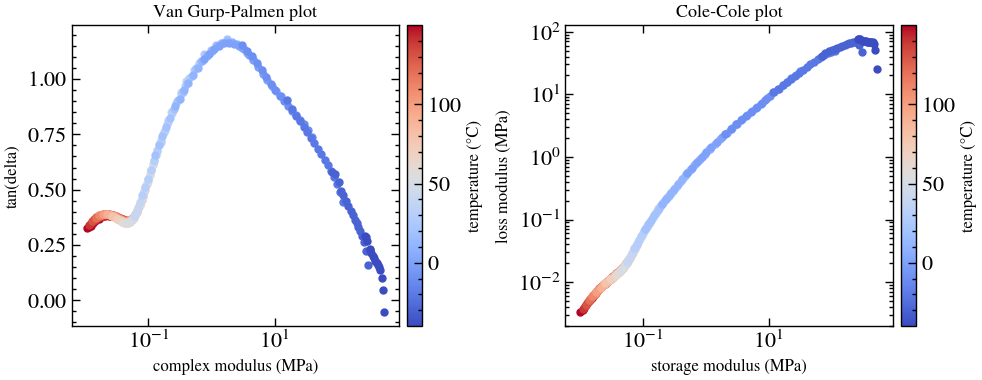

In [2]:
sweep = load("aresg2_trios_frequency_sweep_tts.txt")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_vgp(sweep, ax=axes[0])
plot_cole_cole(sweep, ax=axes[1])
plt.show()

## Temperature-ramped chirps (TORCh)

In a Thermally Optimised Ramped Chirp (TORCh) experiment, OWChirps are
applied continuously during a temperature ramp (Vadillo et al., 2026). This
file already contains the frequency-domain moduli of every chirp, so it is
plotted directly. If the chirps were recorded with the TRIOS Arbitrary Wave
procedure, the file holds only time-domain stress and strain signals; apply
`OWChirpAnalysis` first (Tutorial 3), e.g. `plot_vgp(OWChirpAnalysis()(experiment))`.

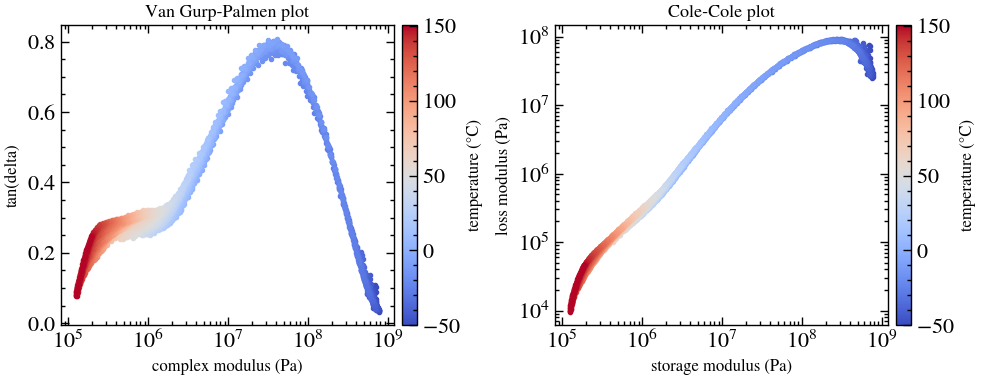

In [3]:
torch = load("dhr30_trios_torch.txt")
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_vgp(torch, ax=axes[0], marker="o", markersize=3)
plot_cole_cole(torch, ax=axes[1], marker="o", markersize=3)
plt.show()

Both functions draw onto an existing axes (`ax`) and colour each measurement
by temperature (`colormap`), with a legend for a few curves or a colour bar for
many (`legend`). They plot any pair of data arrays (`x_name`, `y_name`), can
save the figure (`save`), and forward extra keywords to `ax.plot`. See the
[visualization API](https://3mcloud.github.io/hermes-rheo/visualization.html)
for these options and the other plotting helpers.

## References

- van Gurp, M. and Palmen, J., *Time-temperature superposition for polymeric
  blends*, *Rheology Bulletin* **67**, 5–8 (1998).
- Cole, K. S. and Cole, R. H., *Dispersion and Absorption in Dielectrics —
  I. Alternating Current Characteristics*, *Journal of Chemical Physics*
  **9**, 341–351 (1941). DOI: [10.1063/1.1750906](https://doi.org/10.1063/1.1750906).
- Vadillo, D. C., Perego, A. et al., *TORCh: Thermally Optimised Ramped Chirp
  for time-temperature spectroscopy of polymers*, *Macromolecules* (2026).
  DOI: [10.1021/acs.macromol.6c00679](https://doi.org/10.1021/acs.macromol.6c00679).